In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
df = pd.read_csv("titanic.csv")
print("Dataset Loaded successfully")

Dataset Loaded successfully


In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:",df.shape[1])

Number of rows: 891
Number of columns: 12


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [9]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


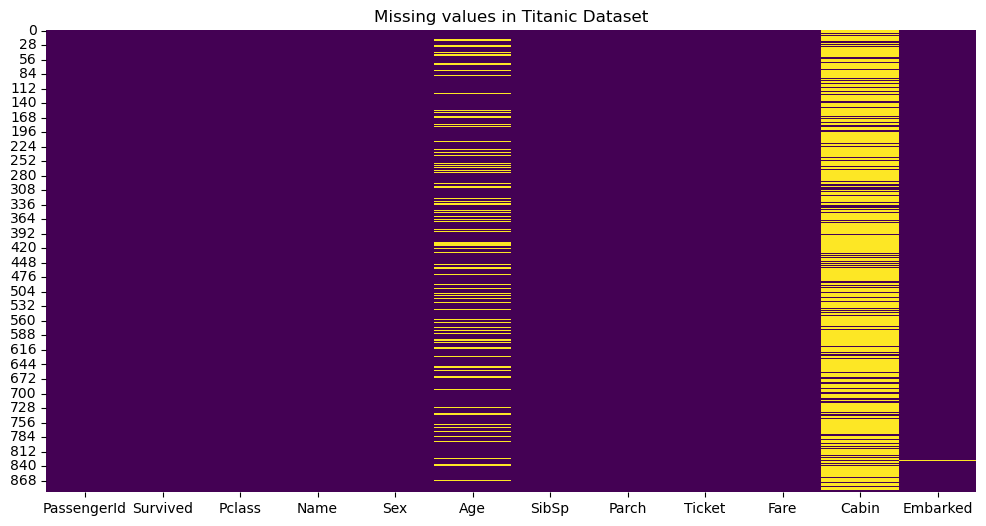

In [10]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(),cbar=False,cmap='viridis')

plt.title("Missing values in Titanic Dataset")
plt.show()

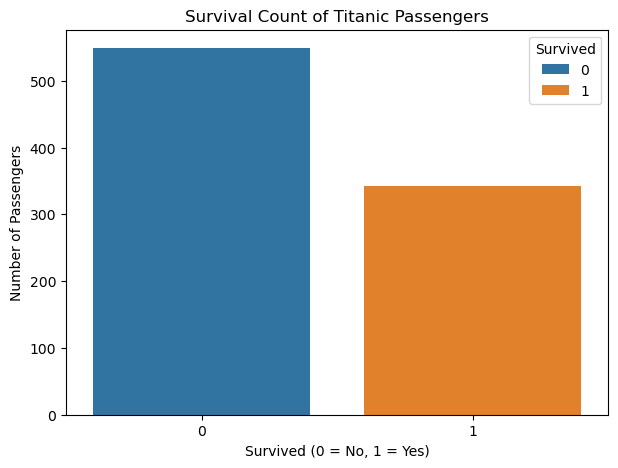

In [11]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Survived', hue='Survived')

plt.title("Survival Count of Titanic Passengers")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

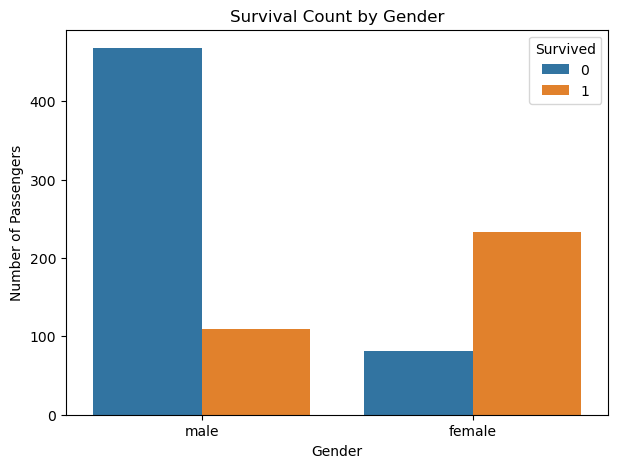

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Sex', hue='Survived')

plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

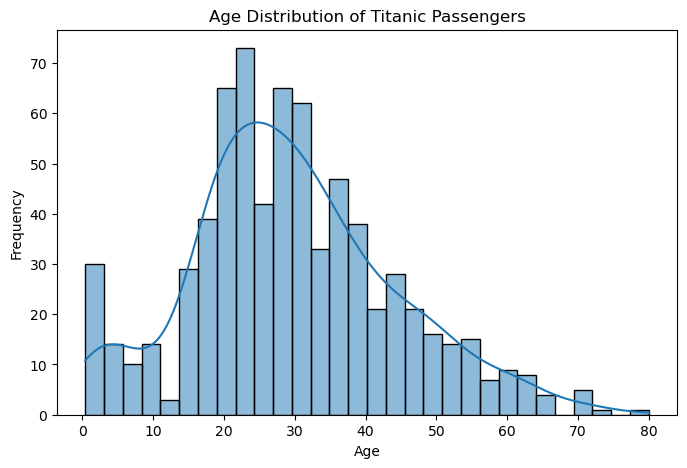

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Age', bins=30, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

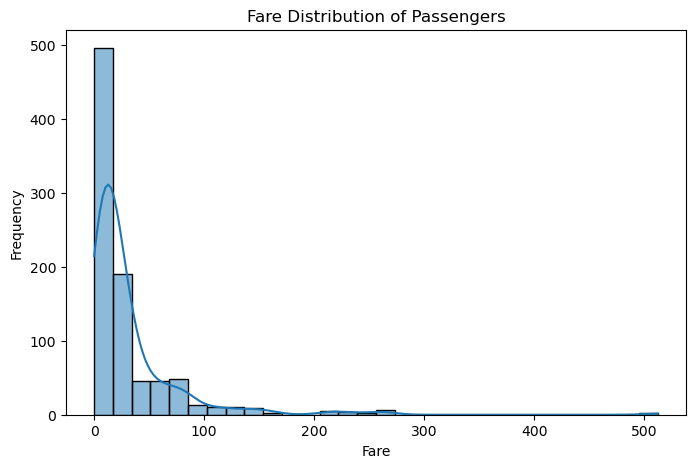

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Fare', bins=30, kde=True)

plt.title("Fare Distribution of Passengers")
plt.xlabel("Fare")
plt.ylabel("Frequency")

plt.show()

In [ ]:

df_clean = df.copy()
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())

print("Age missing values:", df_clean['Age'].isnull().sum())

Age missing values: 0


In [ ]:
df_clean['Cabin'] = df_clean['Cabin'].fillna('Unknown')

print("Cabin missing values:", df_clean['Cabin'].isnull().sum())

Cabin missing values: 0


In [ ]:
df_clean['Embarked'] = df_clean['Embarked'].fillna(
    df_clean['Embarked'].mode()[0]
)

print("Embarked missing values:", df_clean['Embarked'].isnull().sum())

Embarked missing values: 0


In [18]:
print(df_clean.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


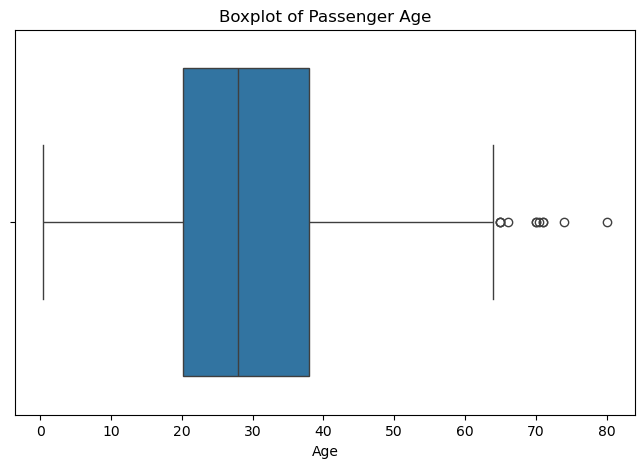

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Age')

plt.title("Boxplot of Passenger Age")
plt.xlabel("Age")

plt.show()

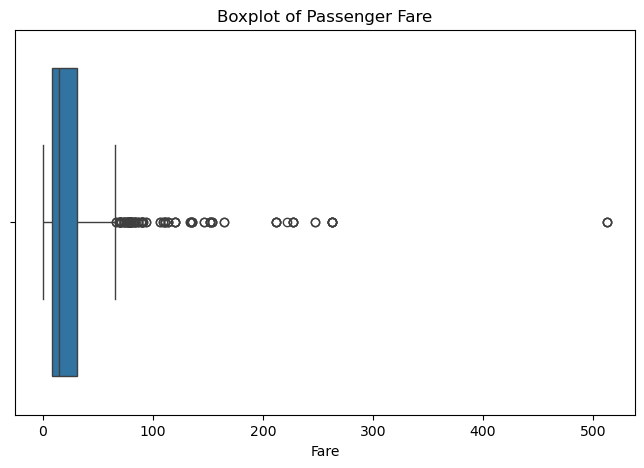

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Fare')

plt.title("Boxplot of Passenger Fare")
plt.xlabel("Fare")

plt.show()

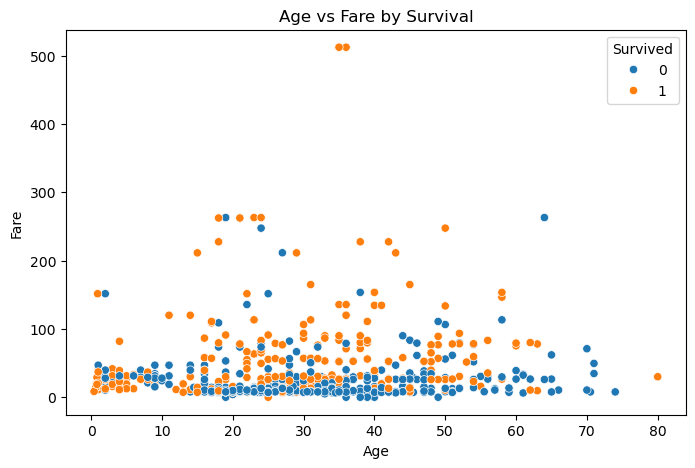

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Age', y='Fare', hue='Survived')

plt.title("Age vs Fare by Survival")
plt.xlabel("Age")
plt.ylabel("Fare")

plt.show()

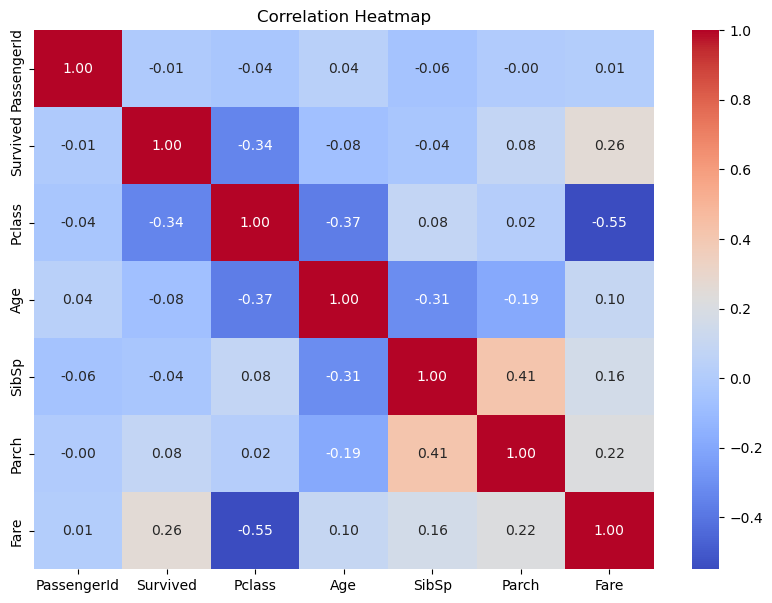

In [22]:
plt.figure(figsize=(10, 7))

sns.heatmap(df.select_dtypes(include='number').corr(),
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title("Correlation Heatmap")

plt.show()

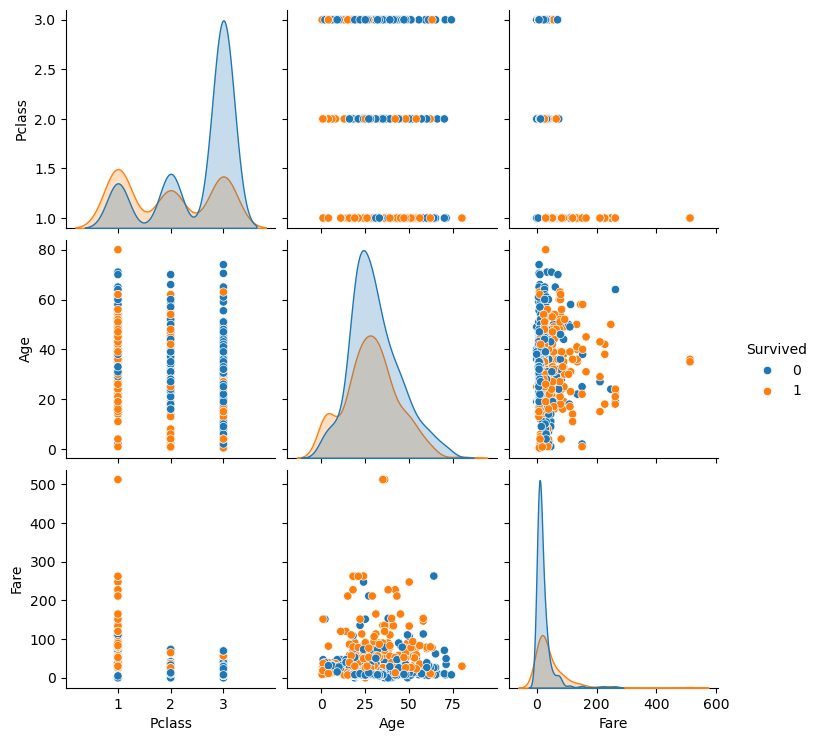

In [23]:
sns.pairplot(
    df[['Survived', 'Pclass', 'Age', 'Fare']],
    hue='Survived'
)

plt.show()

In [24]:
df_clean.to_csv("titanic_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [25]:
# Final cleaned dataset overview

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

df_clean.info()

Original Dataset Shape: (891, 12)
Cleaned Dataset Shape: (891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        891 non-null    object 
 11  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [26]:
print("Total Passengers:", len(df_clean))

print("\nSurvival Rate:")
print(df_clean['Survived'].value_counts(normalize=True) * 100)

print("\nGender-wise Survival Rate:")
print(df_clean.groupby('Sex')['Survived'].mean() * 100)

print("\nClass-wise Survival Rate:")
print(df_clean.groupby('Pclass')['Survived'].mean() * 100)

print("\nAverage Age:", df_clean['Age'].mean())

print("\nAverage Fare:", df_clean['Fare'].mean())

Total Passengers: 891

Survival Rate:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

Gender-wise Survival Rate:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

Class-wise Survival Rate:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

Average Age: 29.36158249158249

Average Fare: 32.204207968574636



# Exploratory Data Analysis on Titanic Dataset

## 1. Introduction
Exploratory Data Analysis (EDA) is used to understand data patterns, identify missing values, detect outliers and discover relationships between variables.

## 2. Dataset Description
The Titanic dataset contains passenger information such as Age, Gender, Passenger Class, Fare and Survival Status.

## 3. Data Cleaning
- Checked missing values.
- Filled missing Age values using Median.
- Filled missing Cabin values with Unknown.
- Filled missing Embarked values using Mode.
- Created a cleaned dataset.

## 4. Data Visualization
The following visualizations were performed:
- Countplot
- Histogram
- Boxplot
- Scatterplot
- Correlation Heatmap
- Pairplot

## 5. Outlier Detection
Used Boxplots and the IQR method to identify outliers in the Fare column.

## 6. Key Findings
Analyzed passenger survival rates, gender-wise survival, passenger class, average age and average fare.

## 7. Conclusion
EDA helped understand passenger characteristics, survival patterns, missing values and relationships between different variables.
